In [1]:
import pandas as pd

train = pd.read_csv("../data/raw/train.csv")
test = pd.read_csv("../data/raw/test.csv")

# Shapes should be (1460, 81) and (1459, 80)
print(train.shape, test.shape)

# Only train should contain the target
print("SalePrice" in train.columns, "SalePrice" in test.columns)

# train should be 1..1460, test 1461..2919
print(train["Id"].min(), train["Id"].max(), test["Id"].min(), test["Id"].max())

(1460, 81) (1459, 80)
True False
1 1460 1461 2919


Train has 1,460 houses and 81 columns (79 features plus Id and SalePrice). Test has 1,459 houses and no SalePrice, which is expected since that's what we predict.

Train Ids go from 1 to 1460 and test Ids from 1461 to 2919, so the two sets don't share any house.

Side note: a text editor or Excel shows one row more than this, because it counts the header line.

In [2]:
# Fail loudly if the raw data is ever wrong
assert train.shape == (1460, 81)
assert test.shape == (1459, 80)
assert "SalePrice" in train.columns and "SalePrice" not in test.columns
assert set(train["Id"]).isdisjoint(test["Id"])  # no house in both sets

If the raw files ever change (wrong download, a file saved from Excel, train and test swapped), these lines stop the notebook right away instead of letting me get different results without noticing.

In [3]:
# Make src/ importable from notebooks/ and reload edited modules automatically
%load_ext autoreload
%autoreload 2
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from src.cv import RAW_DIR, FIGURES_DIR

train = pd.read_csv(RAW_DIR / "train.csv")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# The target for the whole project: log(1 + price)
y = np.log1p(train["SalePrice"])

Paths and the seed come from src/cv.py, so every notebook uses the same ones.

The target is defined once here as log1p(SalePrice). The models will predict this, and at the end I'll use expm1 to get back to dollars.

In [4]:
# Numeric features, excluding the Id and the target itself
num_cols = train.select_dtypes(include="number").columns.drop(["Id", "SalePrice"])
# Text columns; "exclude number" also works with pandas 3's new string dtype
cat_cols = train.select_dtypes(exclude="number").columns

print(len(num_cols), "numeric |", len(cat_cols), "categorical")
print(train[["MSSubClass", "OverallQual", "OverallCond"]].head())

36 numeric | 43 categorical
   MSSubClass  OverallQual  OverallCond
0          60            7            5
1          20            6            8
2          60            7            5
3          70            7            5
4          60            8            5


36 numeric and 43 categorical columns, not counting Id and SalePrice.

Not every numeric column is a real quantity though:
- MSSubClass is a code for the type of dwelling (20 is a 1-story house built 1946 or later, 60 is a 2-story one). 60 isn't three times 20, so I'll treat it as a category.
- MoSold is just the month, and YrSold only has five values (2006 to 2010), so they behave more like labels than numbers.
- OverallQual and OverallCond are scores from 1 to 10. The order means something here, so they stay numeric.

pandas 3 reads text into a new string type, which is why I used exclude="number" instead of include="object".

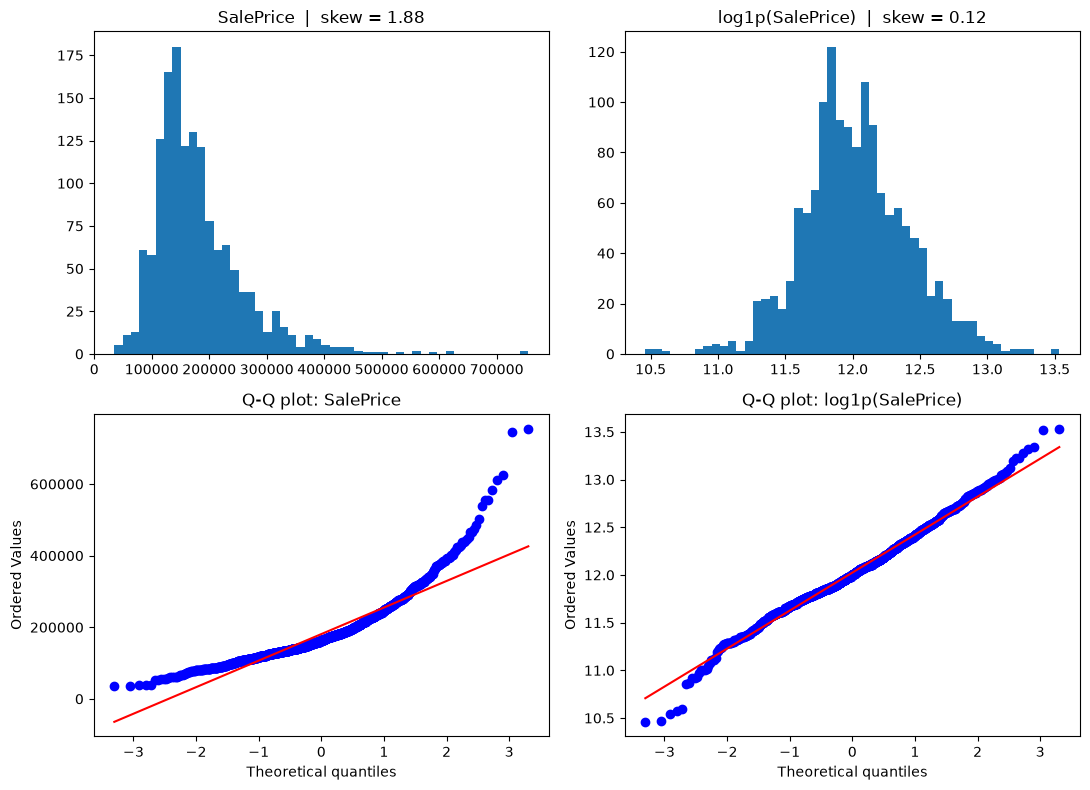

In [5]:
# Histogram (top) and Q-Q plot (bottom) for raw price and log price
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
targets = [(train["SalePrice"], "SalePrice"), (y, "log1p(SalePrice)")]

for col, (data, name) in enumerate(targets):
    axes[0, col].hist(data, bins=50)
    axes[0, col].set_title(f"{name}  |  skew = {stats.skew(data):.2f}")
    stats.probplot(data, dist="norm", plot=axes[1, col])
    axes[1, col].set_title(f"Q-Q plot: {name}")

fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_target_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

The raw price is clearly right-skewed (skew 1.88). Most houses sold between \$100k and \$250k, and a few go all the way up to \$755k. In the Q-Q plot the points bend far above the line on the right, so there are a lot more expensive houses than a normal distribution would give.

After log1p the skew drops to 0.12 and the Q-Q points almost follow the line. The only thing left is a handful of very cheap houses at the bottom left (around \$35k to \$40k), which I'll look at again during error analysis.

This matters for two reasons. With the raw price, the squared error is dominated by the expensive houses, and the errors get bigger as the price grows. With the log, an error is basically a percentage: being 10% off costs the same for a \$100k house and a \$500k house. That's also how Kaggle scores this competition.

So I'll model log1p(SalePrice).

In [6]:
# Pearson correlation of each numeric feature with log price
corr_with_y = train[num_cols].corrwith(y).sort_values(ascending=False)
print("Top 10 positive:\n", corr_with_y.head(10).round(3))
print("\nMost negative:\n", corr_with_y.tail(5).round(3))

Top 10 positive:
 OverallQual     0.817
GrLivArea       0.701
GarageCars      0.681
GarageArea      0.651
TotalBsmtSF     0.612
1stFlrSF        0.597
FullBath        0.595
YearBuilt       0.587
YearRemodAdd    0.566
GarageYrBlt     0.541
dtype: float64

Most negative:
 YrSold          -0.037
LowQualFinSF    -0.038
MSSubClass      -0.074
KitchenAbvGr    -0.148
EnclosedPorch   -0.149
dtype: float64


OverallQual is the strongest feature by a wide margin (0.82), then GrLivArea (0.70). Quality and living area drive the price the most.

A few features in the top 10 measure the same thing twice: GarageCars and GarageArea (garage size), TotalBsmtSF and 1stFlrSF (the first floor sits on the basement), and YearBuilt and GarageYrBlt (the garage is usually built with the house). This will be a problem for linear models later; the heatmap below confirms it.

GarageYrBlt is missing for houses with no garage. corrwith skips those rows, so its correlation only covers houses that have a garage.

The negative correlations are all weak (below 0.15). MSSubClass at -0.07 doesn't mean anything since it's a code, one more reason to make it a category. YrSold is close to zero, so the year of the sale barely matters on its own.

To keep in mind: this is linear correlation only. A feature with a low value can still be useful if the relationship is curved or depends on other features, and a high value doesn't mean the feature causes the price.

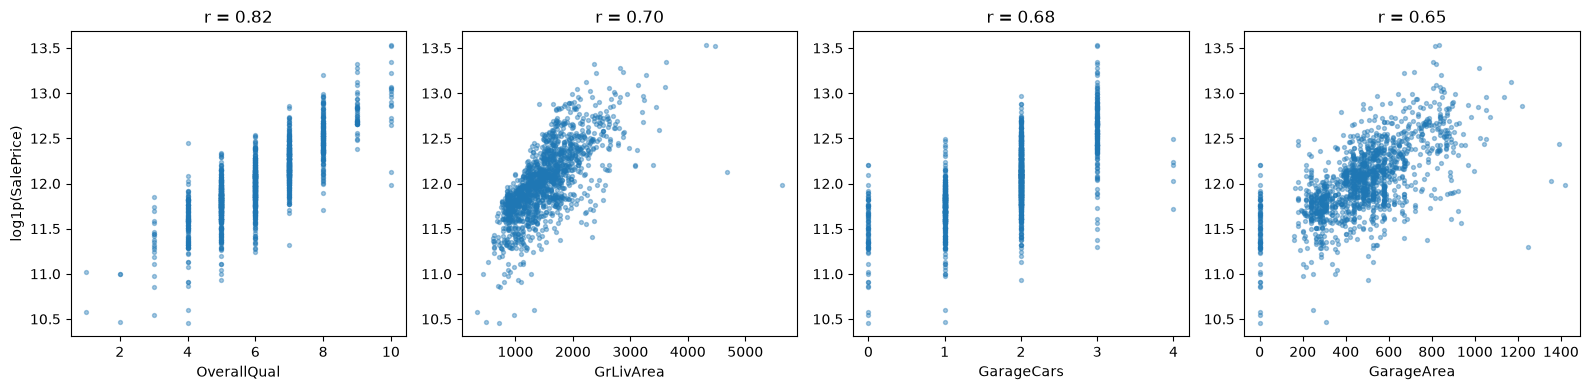

In [7]:
# Scatter of the 4 strongest features against log price
top4 = corr_with_y.index[:4]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, top4):
    ax.scatter(train[col], y, s=8, alpha=0.4)
    ax.set_xlabel(col)
    ax.set_title(f"r = {corr_with_y[col]:.2f}")
axes[0].set_ylabel("log1p(SalePrice)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_top4_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

OverallQual goes up steadily across the 10 levels, but inside each level the price still varies a lot, so quality alone doesn't explain everything.

GrLivArea has a strong upward trend that flattens a bit for the biggest houses. The area is raw here while the price is in log, so taking the log of GrLivArea should straighten it for the linear models.

The two houses at the far right (about 4,700 and 5,600 sq ft) sold for ordinary prices, way below the trend. These are the outliers mentioned in the brief. The other two very large houses (around 4,300 to 4,500 sq ft) follow the trend fine.

GarageCars rises from 0 to 3 cars. The few houses with 4 are cheaper, but there are too few of them to read anything into it.

In GarageArea, the column of points at 0 is the houses with no garage. They form a separate group at the lower end, so a has_garage flag makes sense.

GarageCars and GarageArea look almost the same, which is what you'd expect if they carry the same information.

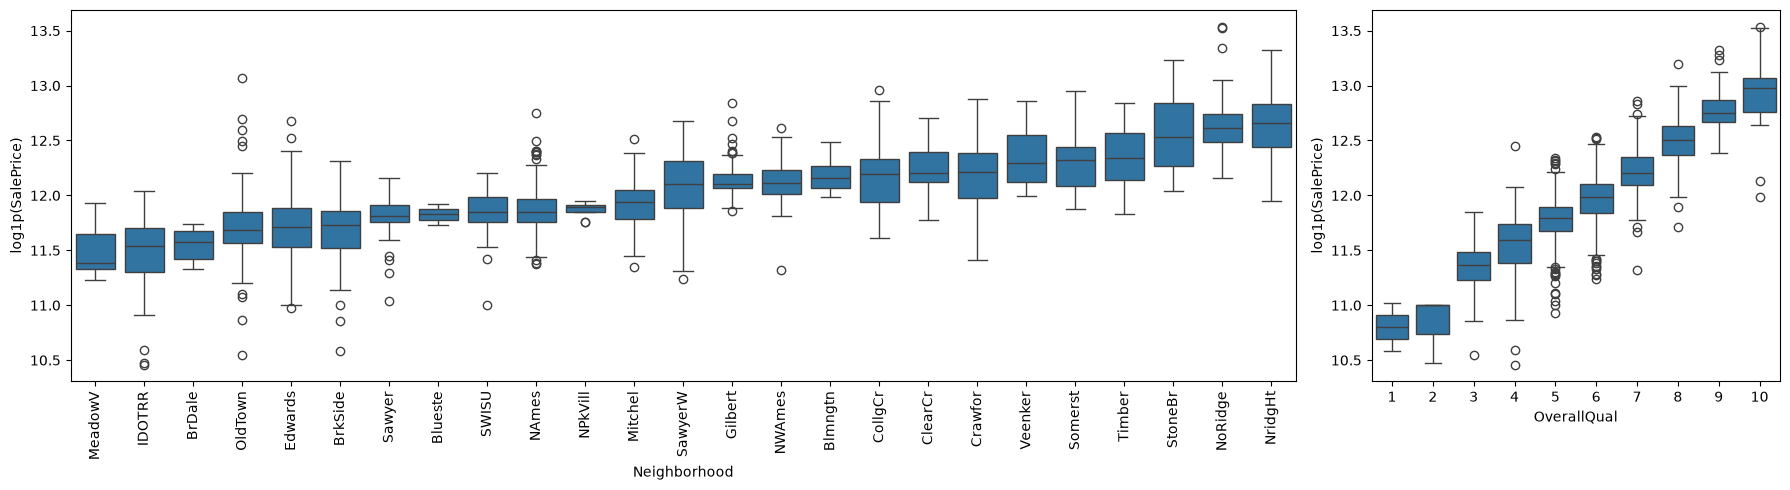

In [8]:
# Neighborhood boxes sorted by median log price so the ranking is readable
order = y.groupby(train["Neighborhood"]).median().sort_values().index

fig, axes = plt.subplots(1, 2, figsize=(18, 5), gridspec_kw={"width_ratios": [3, 1]})
sns.boxplot(x=train["Neighborhood"], y=y, order=order, ax=axes[0])
axes[0].tick_params(axis="x", rotation=90)
axes[0].set_ylabel("log1p(SalePrice)")

sns.boxplot(x=train["OverallQual"], y=y, ax=axes[1])
axes[1].set_ylabel("log1p(SalePrice)")

fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_neighborhood_quality_boxplots.png", dpi=150, bbox_inches="tight")
plt.show()

Neighborhood makes a big difference. The cheapest one (MeadowV) has a median around 11.4 in log price and the most expensive (NridgHt) around 12.65. A gap of about 1.25 in log is roughly 3.5 times the price, just from location.

Some neighborhoods like Blueste and NPkVill have very narrow boxes because they only have a few houses, so I shouldn't trust their medians much. That matters if I try target encoding later, and for one-hot columns with almost no data.

Most neighborhoods overlap in the middle: the location sets the general price level, and the house itself (quality, size) explains the rest. There's no natural order between neighborhoods, so one-hot encoding is the right choice for linear models.

For OverallQual, the median goes from about 10.8 at quality 1 to about 13.0 at quality 10. From quality 4 up, every extra point adds around 0.2 to 0.3 in log price, which is roughly 22% to 35% more in price. The steps are fairly even, so keeping it as one numeric feature works for a linear model. They get a little bigger at the top (8 to 10); a tree model will pick that up on its own.

Levels 1 and 2 have very few houses. Quality 5 and 6 have a lot of low outliers, average houses that sold well below normal. Worth checking their SaleCondition later.

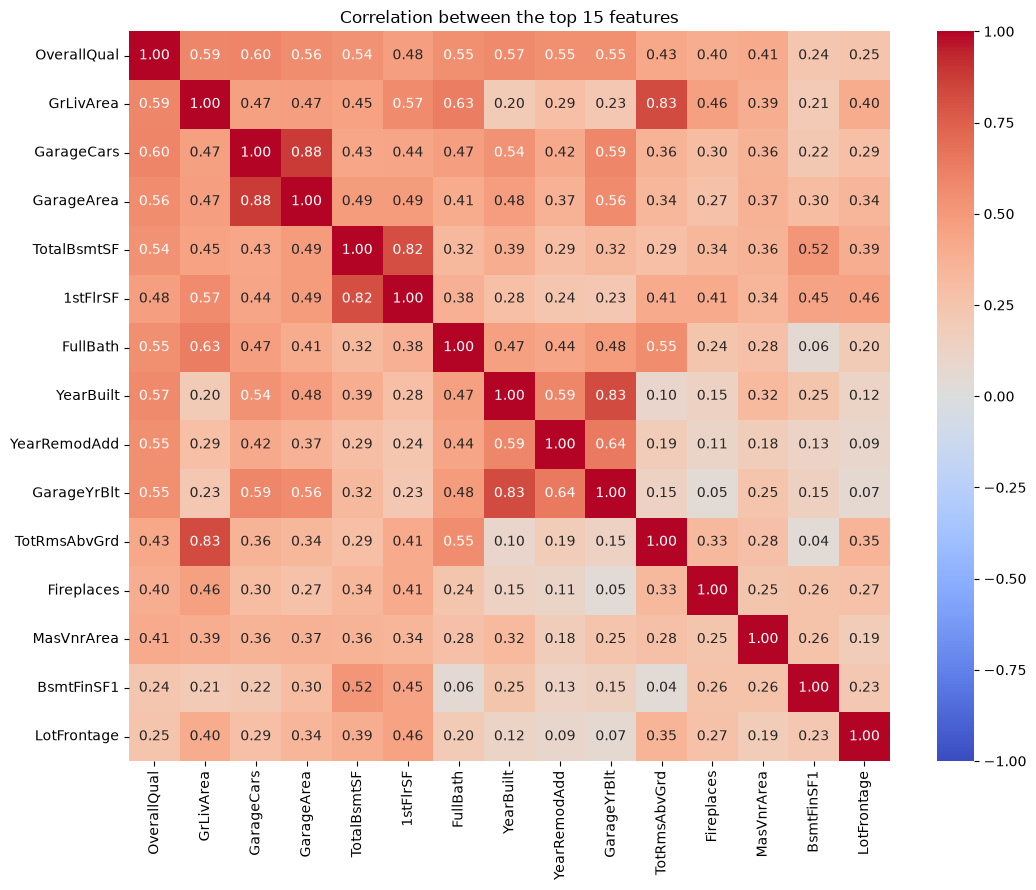

GarageCars   GarageArea      0.882
YearBuilt    GarageYrBlt     0.826
GrLivArea    TotRmsAbvGrd    0.825
TotalBsmtSF  1stFlrSF        0.820
dtype: float64


In [9]:
# Correlation between the 15 strongest features themselves (not with the target)
top15 = corr_with_y.abs().sort_values(ascending=False).index[:15]
corr_matrix = train[top15].corr()

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation between the top 15 features")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_top15_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

# List each redundant pair once (|r| > 0.8), using only the upper triangle
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape, dtype=bool), k=1))
pairs = upper.stack().loc[lambda s: s.abs() > 0.8].sort_values(ascending=False)
print(pairs.round(3))

Four pairs are above 0.8:
- GarageCars and GarageArea: 0.88
- YearBuilt and GarageYrBlt: 0.83
- GrLivArea and TotRmsAbvGrd: 0.83
- TotalBsmtSF and 1stFlrSF: 0.82

These are the three pairs I expected, plus GrLivArea and TotRmsAbvGrd, which makes sense since a bigger house has more rooms. TotRmsAbvGrd wasn't in the top 10 earlier, so it only shows up here.

For plain linear regression this means unstable coefficients. The model can't tell which of the two features deserves the credit, so the weights can swing a lot or even get the wrong sign. The predictions are mostly fine, but the coefficients become hard to interpret. I'll measure this with VIF in Phase 4 and see how Ridge and Lasso handle it in Phase 5.

OverallQual also correlates around 0.55 to 0.60 with size, age and garage. Better houses tend to be bigger and newer, so part of the "quality" effect overlaps with those.

        Id  GrLivArea  SalePrice  OverallQual Neighborhood SaleCondition
523    524       4676     184750           10      Edwards       Partial
691    692       4316     755000           10      NoRidge        Normal
1182  1183       4476     745000           10      NoRidge       Abnorml
1298  1299       5642     160000           10      Edwards       Partial


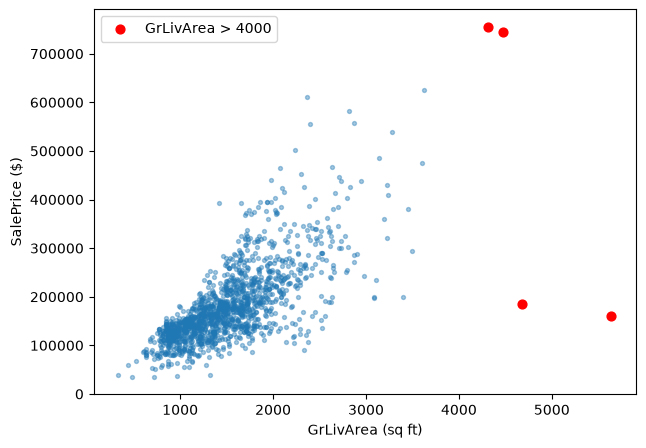

In [10]:
# Houses above 4,000 sq ft, with context to judge whether they are errors or special sales
big = train.loc[train["GrLivArea"] > 4000,
                ["Id", "GrLivArea", "SalePrice", "OverallQual", "Neighborhood", "SaleCondition"]]
print(big)

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(train["GrLivArea"], train["SalePrice"], s=8, alpha=0.4)
ax.scatter(big["GrLivArea"], big["SalePrice"], s=40, color="red", label="GrLivArea > 4000")
ax.set_xlabel("GrLivArea (sq ft)")
ax.set_ylabel("SalePrice ($)")
ax.legend()
fig.savefig(FIGURES_DIR / "01_grlivarea_outliers.png", dpi=150, bbox_inches="tight")
plt.show()

Four houses are above 4,000 sq ft, and all four have OverallQual 10.

- 692 and 1183 are in NoRidge and sold for \$755,000 and \$745,000, the two most expensive houses in the data. Huge and expensive, so they fit the trend. (1183 is marked Abnorml, but its price looks normal for that house.)
- 524 and 1299 are in Edwards, one of the cheaper neighborhoods, and sold for only \$184,750 and \$160,000. Both are Partial sales, meaning the house wasn't finished when it was assessed (new construction sold early).

So the two cheap ones aren't just "big houses". They're unusual sales, and their prices probably don't reflect market value. The dataset's author recommends removing every house over 4,000 sq ft, but that would also remove 692 and 1183, which look legitimate.

For now I'm keeping all four. In Phase 5 I'll run the models with and without 524 and 1299 and decide based on the results.

              train_%  test_%
PoolQC          99.52   99.79
MiscFeature     96.30   96.50
Alley           93.77   92.67
Fence           80.75   80.12
MasVnrType      59.73   61.27
FireplaceQu     47.26   50.03
LotFrontage     17.74   15.56
GarageCond       5.55    5.35
GarageFinish     5.55    5.35
GarageQual       5.55    5.35
GarageYrBlt      5.55    5.35
GarageType       5.55    5.21
BsmtExposure     2.60    3.02
BsmtFinType2     2.60    2.88
BsmtCond         2.53    3.08
BsmtQual         2.53    3.02
BsmtFinType1     2.53    2.88
MasVnrArea       0.55    1.03
Electrical       0.07    0.00
MSZoning         0.00    0.27
BsmtFullBath     0.00    0.14
BsmtHalfBath     0.00    0.14
Functional       0.00    0.14
Utilities        0.00    0.14
BsmtFinSF1       0.00    0.07
BsmtFinSF2       0.00    0.07
BsmtUnfSF        0.00    0.07
Exterior1st      0.00    0.07
Exterior2nd      0.00    0.07
GarageArea       0.00    0.07
GarageCars       0.00    0.07
KitchenQual      0.00    0.07
SaleType  

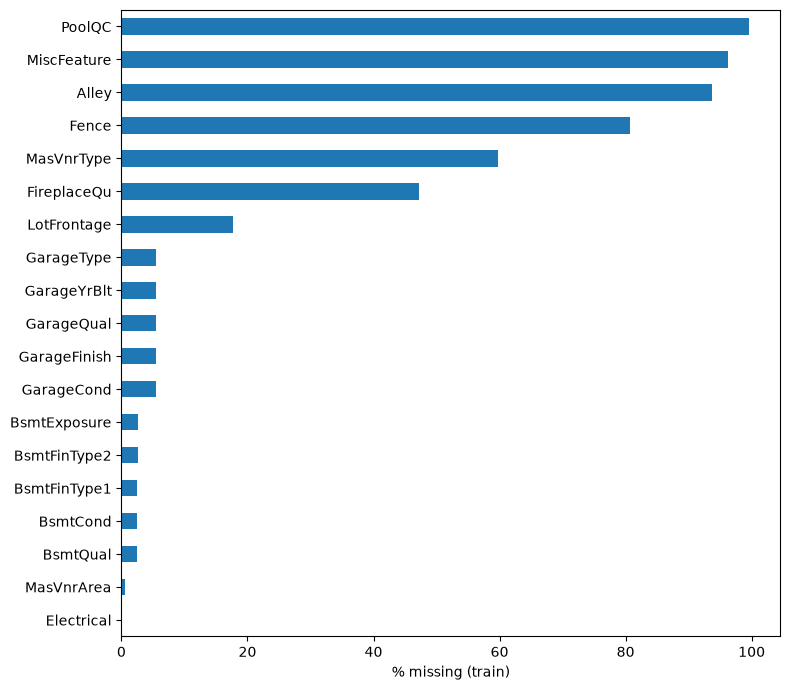

In [11]:
# Test is loaded here only to see WHICH columns are missing; nothing is learned from it
test = pd.read_csv(RAW_DIR / "test.csv")

# Percentage of missing values per column, train and test side by side
missing = pd.DataFrame({
    "train_%": train.isna().mean() * 100,
    "test_%": test.isna().mean() * 100,
}).round(2)
missing = missing[(missing["train_%"] > 0) | (missing["test_%"] > 0)]
missing = missing.sort_values(["train_%", "test_%"], ascending=False)
print(missing.to_string())

# Columns that are complete in train but have gaps in test: the pipeline must still handle them
only_test = missing[(missing["train_%"] == 0) & (missing["test_%"] > 0)].index.tolist()
print("\nMissing in test only:", only_test)

# Bar chart of missing % in train
fig, ax = plt.subplots(figsize=(8, 7))
missing.loc[missing["train_%"] > 0, "train_%"].sort_values().plot.barh(ax=ax)
ax.set_xlabel("% missing (train)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_missing_values.png", dpi=150, bbox_inches="tight")
plt.show()

19 columns have missing values in train, but most of them aren't really missing. In data_description.txt, NA means the house doesn't have that feature.
- PoolQC (99.5%), MiscFeature (96.3%), Alley (93.8%) and Fence (80.8%): almost no house has these, so NA just means none.
- FireplaceQu (47.3%): houses without a fireplace.
- The garage columns (5.55%, 81 houses): no garage.
- The basement columns (about 2.5%, 37 houses): no basement.
- MasVnrType (59.7%) looks strange at first. pandas reads the word "None" as missing, and "None" here means no masonry veneer. Only 8 of these houses also have MasVnrArea missing; those 8 are the truly missing ones.

The really missing columns are LotFrontage (17.7%) and Electrical (one house).

Test follows the same pattern, plus 15 columns that are complete in train but have 1 to 4 missing houses in test (MSZoning, Utilities, KitchenQual, GarageCars and others). The pipeline has to handle these too, so the imputers need to cover every column, not only the ones with gaps in train.

In [12]:
# For each category column, compare its NA count with "size = 0" in its numeric partner
checks = {
    "PoolQC": "PoolArea",
    "FireplaceQu": "Fireplaces",
    "GarageType": "GarageArea",
    "GarageYrBlt": "GarageArea",
    "BsmtQual": "TotalBsmtSF",
    "BsmtExposure": "TotalBsmtSF",
}
for name, df in [("train", train), ("test", test)]:
    print(f"--- {name} ---")
    for cat, num in checks.items():
        na_cat = df[cat].isna()
        zero_num = df[num] == 0
        print(f"{cat:13s} NA: {na_cat.sum():4d} | {num:12s} == 0: {zero_num.sum():4d} "
              f"| both: {(na_cat & zero_num).sum():4d}")

--- train ---
PoolQC        NA: 1453 | PoolArea     == 0: 1453 | both: 1453
FireplaceQu   NA:  690 | Fireplaces   == 0:  690 | both:  690
GarageType    NA:   81 | GarageArea   == 0:   81 | both:   81
GarageYrBlt   NA:   81 | GarageArea   == 0:   81 | both:   81
BsmtQual      NA:   37 | TotalBsmtSF  == 0:   37 | both:   37
BsmtExposure  NA:   38 | TotalBsmtSF  == 0:   37 | both:   37
--- test ---
PoolQC        NA: 1456 | PoolArea     == 0: 1453 | both: 1453
FireplaceQu   NA:  730 | Fireplaces   == 0:  730 | both:  730
GarageType    NA:   76 | GarageArea   == 0:   76 | both:   76
GarageYrBlt   NA:   78 | GarageArea   == 0:   76 | both:   76
BsmtQual      NA:   44 | TotalBsmtSF  == 0:   41 | both:   41
BsmtExposure  NA:   44 | TotalBsmtSF  == 0:   41 | both:   41


In train the numbers match almost everywhere: NA in the quality column happens exactly when the matching area or count is 0. So for pools, fireplaces, garages and basements, NA really means absent, and filling with "None" (and 0 for the matching numbers) is correct.

The only exception in train is BsmtExposure: 38 NA but only 37 houses without a basement. So one house has a basement but its exposure is missing. That one is truly missing.

Test has a few more of these:
- PoolQC: 1456 NA but 1453 houses without a pool, so 3 houses have a pool with no quality recorded
- BsmtQual and BsmtExposure: 44 NA against 41 houses without a basement
- GarageYrBlt: 78 NA against 76 houses without a garage

These can't just be filled with "None", because the feature exists. They need a real imputation (most frequent value, for example). That's the third kind of missing value in the brief.

In [13]:
# LotFrontage is truly missing (every lot touches a street); does it depend on location?
lf = train.groupby("Neighborhood")["LotFrontage"].agg(median="median", n_known="count")
lf["missing_%"] = (train["LotFrontage"].isna()
                   .groupby(train["Neighborhood"]).mean().mul(100).round(1))
print(lf.sort_values("median").to_string())

              median  n_known  missing_%
Neighborhood                            
BrDale          21.0       16        0.0
MeadowV         21.0       15       11.8
NPkVill         24.0        7       22.2
Blueste         24.0        2        0.0
Blmngtn         43.0       14       17.6
BrkSide         52.0       51       12.1
IDOTRR          60.0       34        8.1
OldTown         60.0      109        3.5
SWISU           60.0       23        8.0
StoneBr         61.5       20       20.0
Gilbert         65.0       49       38.0
Edwards         65.5       92        8.0
SawyerW         66.5       50       15.3
Veenker         68.0        7       36.4
CollgCr         70.0      126       16.0
Sawyer          71.0       48       35.1
NAmes           73.0      186       17.3
Mitchel         73.0       36       26.5
Somerst         73.5       78        9.3
Crawfor         74.0       41       19.6
ClearCr         80.0       13       53.6
NWAmes          80.0       45       38.4
Timber          

LotFrontage changes a lot with location. The median goes from 21 ft in BrDale and MeadowV to 91 ft in NoRidge, more than four times bigger. One global median would be wrong for most neighborhoods, so filling with the neighborhood median makes more sense.

Two things to watch:
- The share of missing values isn't even (over 50% in ClearCr, under 2% in NridgHt).
- Some neighborhoods have very few known values (Blueste has 2, NPkVill and Veenker have 7). Inside a CV fold a small neighborhood could end up with no known values at all, so the imputer needs a fallback to the global median.

The medians also have to be computed on the training fold only, inside the pipeline.

## Where I am after the EDA

The target will be log1p(SalePrice). It fixes the skew and matches how the competition is scored.

The features that matter most are quality, living area, garage, basement size, age and neighborhood. Several of them come in pairs that say the same thing, which will matter for linear regression.

Most missing values just mean the house doesn't have that feature. Only LotFrontage and a handful of single values are really missing.

Two houses in Edwards (524 and 1299) are huge but sold cheap as partial sales. I'm not removing them yet.

Next, in Phase 2:
- Fill the "absent" NAs with "None" for categories and 0 for the matching numbers, and add has_ flags (pool, garage, basement, fireplace, 2nd floor)
- Fill LotFrontage with the neighborhood median (with a global fallback) inside the pipeline, and the few truly missing values with the most frequent value
- Make MSSubClass a category, map the quality columns (Po to Ex) to numbers, and one-hot the rest
- Log-transform the skewed numeric features for the linear models
- Build the new features: TotalSF, TotalBath, HouseAge, RemodAge, TotalPorchSF

Later on: VIF for multicollinearity in Phase 4, and the outlier experiment with and without 524 and 1299 in Phase 5.